1. Generate a simulated two-class data set with 100 observations and
two features in which there is a visible but non-linear separation between the two classes. Show that in this setting, a support vector
machine with a polynomial kernel (with degree greater than 1) or a
radial kernel will outperform a support vector classifier on the training data. Which technique performs best on the test data? Make
plots and report training and test error rates in order to back up
your assertions.

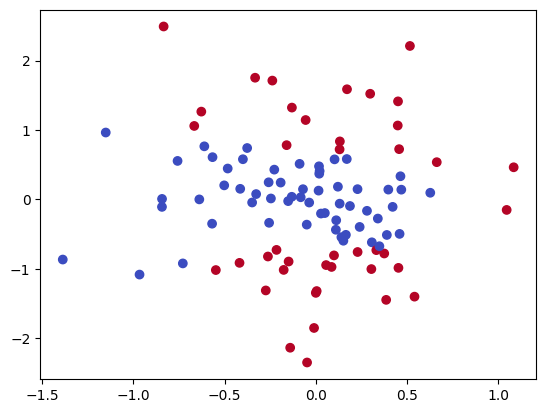

In [15]:
import numpy as np
from matplotlib.pyplot import subplots, cm

rng = np.random.default_rng(1)

X1 = rng.normal(0, rng.random(), 100)
X2 = rng.normal(0, rng.random(), 100)
y = np.where(X1 ** 3 + X2 ** 2 > 0.5, 1, -1)

fig, ax = subplots()

ax.scatter(X1, X2, c=y, cmap=cm.coolwarm);

In [16]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.DataFrame({"X1": X1, "X2": X2, "y": y})

X = df.drop(columns="y")

X_train, X_test, y_train, y_test = train_test_split(X, df["y"], test_size=0.25, random_state=1)

In [17]:
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, accuracy_score

svc_linear = SVC(kernel="linear")
svm_poly = SVC(kernel="poly", degree=2)
svm_rbf = SVC(kernel="rbf")

In [18]:
svc_linear.fit(X_train, y_train)
scv_linear_train_predict = svc_linear.predict(X_train)
scv_linear_predict = svc_linear.predict(X_test)

svm_poly.fit(X_train, y_train)
svm_poly_train_predict = svm_poly.predict(X_train)
svm_poly_predict = svm_poly.predict(X_test)

svm_rbf.fit(X_train, y_train)
svm_rbf_train_predict = svm_rbf.predict(X_train)
svm_rbf_predict = svm_rbf.predict(X_test)

In [19]:
print("SVC LINEAR TRAIN ERROR RATE", 1 - accuracy_score(y_train, scv_linear_train_predict))
print("SVM POLY TRAIN ERROR RATE", 1 - accuracy_score(y_train, svm_poly_train_predict))
print("SVM RBF TRAIN ERROR RATE", 1 - accuracy_score(y_train, svm_rbf_train_predict))

SVC LINEAR TRAIN ERROR RATE 0.4
SVM POLY TRAIN ERROR RATE 0.07999999999999996
SVM RBF TRAIN ERROR RATE 0.026666666666666616


In [20]:
print("SVC LINEAR TEST ERROR RATE", 1 - accuracy_score(y_test, scv_linear_predict))
print("SVM POLY TEST ERROR RATE", 1 - accuracy_score(y_test, svm_poly_predict))
print("SVM RBF TEST ERROR RATE", 1 - accuracy_score(y_test, svm_rbf_predict))

SVC LINEAR TEST ERROR RATE 0.43999999999999995
SVM POLY TEST ERROR RATE 0.19999999999999996
SVM RBF TEST ERROR RATE 0.16000000000000003


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


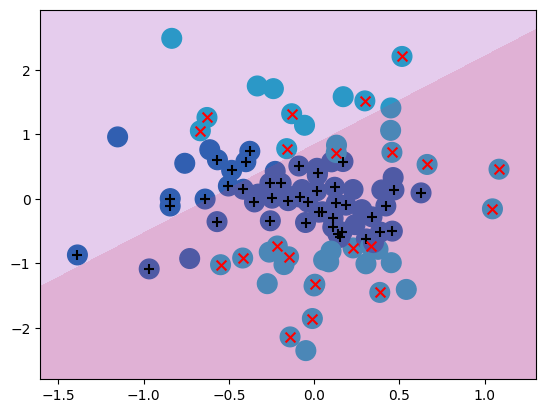

In [21]:
from ISLP.svm import plot as plot_svm

fig, ax = subplots()
X_test_reset = X_test.reset_index(drop=True)
y_test_reset = y_test.reset_index(drop=True)

plot_svm(X, y, svc_linear, ax=ax);

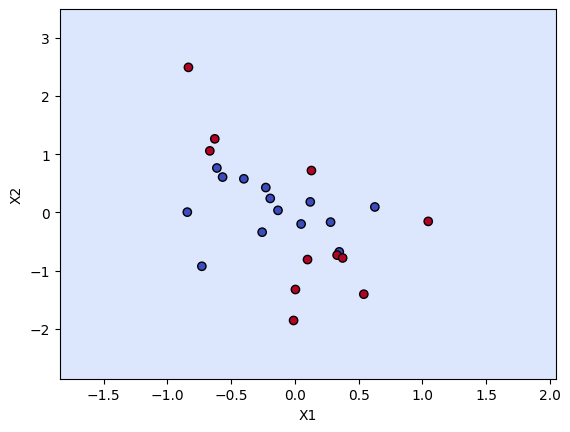

In [22]:
from sklearn.inspection import DecisionBoundaryDisplay

disp = DecisionBoundaryDisplay.from_estimator(
    svc_linear, X_test, response_method="predict",
    alpha=0.3, cmap=cm.coolwarm
)
disp.ax_.scatter(X_test.iloc[:,0], X_test.iloc[:,1], c=y_test, cmap=cm.coolwarm, edgecolors="k");

<div style="border-top: 2px solid green;"></div>

2. We have seen that we can fit an SVM with a non-linear kernel in order
to perform classification using a non-linear decision boundary. We will
now see that we can also obtain a non-linear decision boundary by
performing logistic regression using non-linear transformations of the
features.

In [23]:
# (a) Generate a data set with n = 500 and p = 2, such that the obser-
# vations belong to two classes with a quadratic decision boundary
# between them.

rng = np.random.default_rng(5)
x1 = rng.uniform(size=500) - 0.5
x2 = rng.uniform(size=500) - 0.5
y = x1**2 - x2**2 > 0

df = pd.DataFrame({"x1": x1, "x2": x2, "y": y})
df

,x1,x2,y
0,0.305003,-0.256576,True
1,0.307941,0.211346,True
2,0.015326,0.208829,False
3,-0.214199,-0.078177,True
4,-0.446069,-0.040580,True
...,...,...,...
495,-0.094687,0.289493,False
496,-0.259470,-0.444608,False
497,-0.080933,-0.335240,False
498,0.181635,0.382872,False


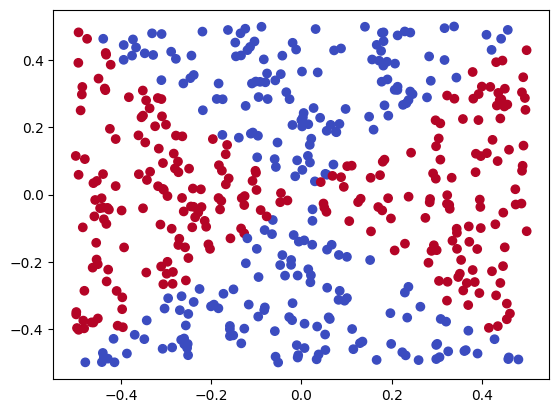

In [24]:
# (b) Plot the observations, colored according to their class labels.
# Your plot should display X1 on the x-axis, and X2 on the y-
# axis.

fig, ax = subplots()
ax.scatter(x1, x2, c=y, cmap=cm.coolwarm);

In [25]:
# (c) Fit a logistic regression model to the data, 
# using X1 and X2 as predictors.

from sklearn.linear_model import LogisticRegression

X = df.drop(columns="y")

logit = LogisticRegression()
logit.fit(X, y)
logit.coef_

array([[-0.15143042,  0.08184281]])

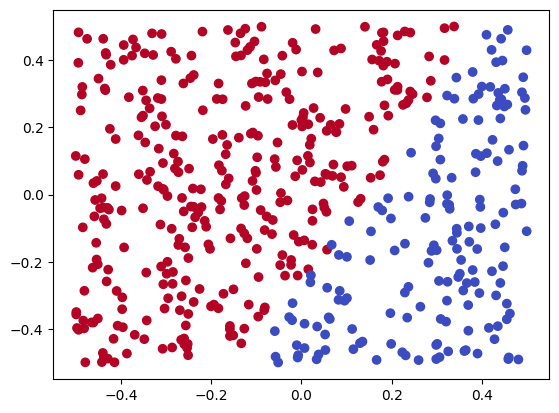

In [26]:
# (d) Apply this model to the training data in order to obtain a 
# predicted class label for each training observation. Plot the 
# observations, colored according to the predicted class labels. The
# decision boundary should be linear.

logit_pred = logit.predict(X)

fig, ax = subplots()

ax.scatter(x1, x2, c=logit_pred, cmap=cm.coolwarm);

In [27]:
# (e) Now fit a logistic regression model to the data using non-linear
# functions of X1 and X2 as predictors.

df["x1_sq"] = df["x1"] ** 2
df["x2_sq"] = df["x2"] ** 2
df["x1_x2"] = df["x1"] * df["x2"]

X_poly = df.drop(columns="y")

poly_logit = LogisticRegression()
poly_logit.fit(X_poly, y)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


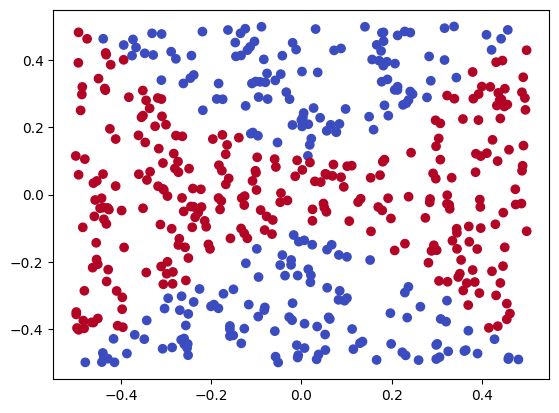

In [28]:
# (f) Apply this model to the training data in order to obtain a 
# predicted class label for each training observation. Plot the 
# observations, colored according to the predicted class labels. The
# decision boundary should be obviously non-linear. If it is not,
# then repeat (a)–(e) until you come up with an example in which
# the predicted class labels are obviously non-linear.

poly_logit_pred = poly_logit.predict(X_poly)

fig, ax = subplots()

ax.scatter(x1, x2, c=poly_logit_pred, cmap=cm.coolwarm);

In [29]:
accuracy_score(y, logit_pred), accuracy_score(y, poly_logit_pred)

(0.43, 0.958)

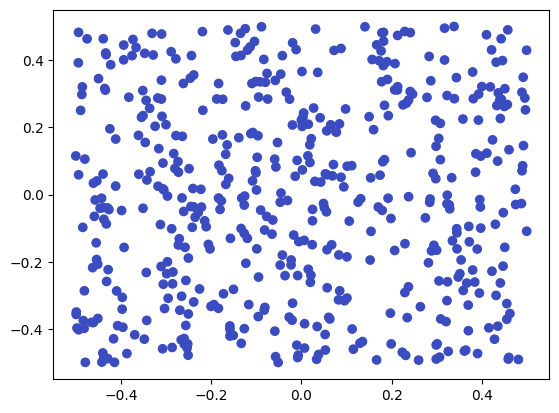

In [30]:
# (g) Fit a support vector classifier to the data with X1 and X2 as
# predictors. Obtain a class prediction for each training 
# observation. Plot the observations, colored according to the predicted
# class labels.

svc = SVC(C=1, kernel="linear")

svc.fit(X, y)

svc_pred = svc.predict(X)

fig, ax = subplots()

ax.scatter(x1, x2, c=svc_pred, cmap=cm.coolwarm);

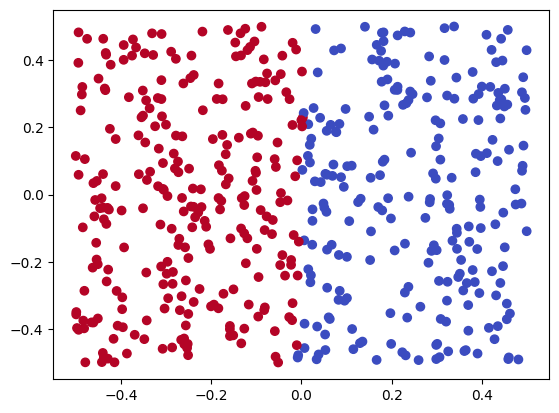

In [31]:
svc = SVC(C=10, kernel="linear")

svc.fit(X, y)

svc_pred = svc.predict(X)

fig, ax = subplots()

ax.scatter(x1, x2, c=svc_pred, cmap=cm.coolwarm);

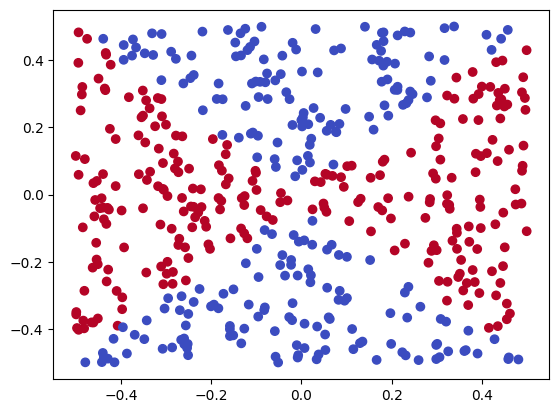

In [32]:
# (h) Fit a SVM using a non-linear kernel to the data. Obtain a class
# prediction for each training observation. Plot the observations,
# colored according to the predicted class labels.

svm = SVC(kernel="rbf", gamma=10, C=10)
svm.fit(X, y)
svm_pred = svm.predict(X)

fig, ax = subplots()

ax.scatter(x1, x2, c=svm_pred, cmap=cm.coolwarm);

In [33]:
accuracy_score(y, svm_pred)

0.984

<div style="border-top: 2px solid green;"></div>

3. At the end of Section 9.6.1, it is claimed that in the case of data that is
just barely linearly separable, a support vector classifier with a small
value of C that misclassifies a couple of training observations may
perform better on test data than one with a huge value of C that does
not misclassify any training observations. You will now investigate
this claim.

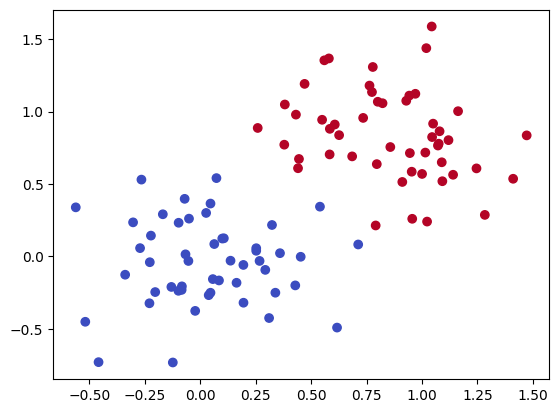

In [34]:
# (a) Generate two-class data with p = 2 in such a way that the classes
# are just barely linearly separable.

rng = np.random.default_rng(2)
X = rng.standard_normal((100, 2)) * 0.3
y = np.array([-1]*50 + [1]*50)
X[y==1] += .85

fig, ax = subplots()
ax.scatter(X[:,0], X[:,1], c=y, cmap=cm.coolwarm);

In [35]:
# (b) Compute the cross-validation error rates for support vector
# classifiers with a range of C values. How many training 
# observations are misclassified for each value of C considered, and how
# does this relate to the cross-validation errors obtained?

from sklearn.model_selection import KFold, GridSearchCV

k_fold = KFold(n_splits=5, shuffle=True, random_state=2)

grid = GridSearchCV(
    estimator=SVC(kernel="linear"),
    param_grid={"C": [0.001, 0.01, 0.1, 1, 5, 10, 100, 1000]},
    refit=True,
    cv=k_fold,
    scoring="accuracy"
)

grid.fit(X, y)

print("Best C", grid.best_params_)
print("Best Accuracy", grid.best_score_)
print("params", grid.cv_results_["params"])
print("mean_test_score", grid.cv_results_["mean_test_score"])

Best C {'C': 0.1}
Best Accuracy 0.9800000000000001
params [{'C': 0.001}, {'C': 0.01}, {'C': 0.1}, {'C': 1}, {'C': 5}, {'C': 10}, {'C': 100}, {'C': 1000}]
mean_test_score [0.36 0.38 0.98 0.98 0.98 0.97 0.97 0.97]


In [36]:
for C in [0.001, 0.01, 0.1, 1, 5, 10, 100, 1000]:
    svc_c = SVC(kernel="linear", C=C)
    svc_c.fit(X, y)
    pred = svc_c.predict(X)
    n_errors = (pred != y).sum()
    print(f"C={C}: train errors = {n_errors}")

C=0.001: train errors = 2
C=0.01: train errors = 2
C=0.1: train errors = 0
C=1: train errors = 1
C=5: train errors = 1
C=10: train errors = 0
C=100: train errors = 0
C=1000: train errors = 0


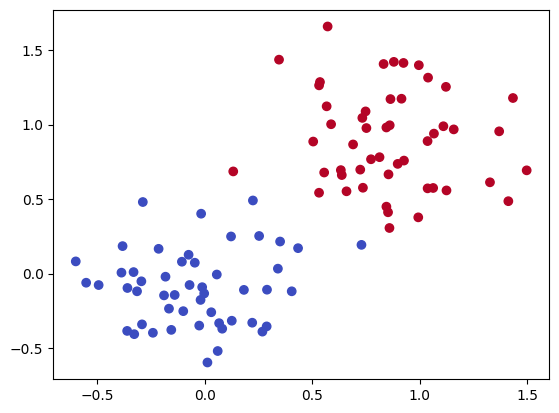

In [37]:
# (c) Generate an appropriate test data set, and compute the test
# errors corresponding to each of the values of C considered. Which
# value of C leads to the fewest test errors, and how does this
# compare to the values of C that yield the fewest training errors
# and the fewest cross-validation errors?

rng = np.random.default_rng(5)
X_test = rng.standard_normal((100, 2)) * 0.3
y_test = np.array([-1]*50 + [1]*50)
X_test[y==1] += .85

fig, ax = subplots()
ax.scatter(X_test[:,0], X_test[:,1], c=y_test, cmap=cm.coolwarm);

In [38]:
for C in [0.001, 0.01, 0.1, 1, 5, 10, 100, 1000]:
    svc_c = SVC(kernel="linear", C=C)
    svc_c.fit(X, y)
    pred = svc_c.predict(X_test)
    n_errors = (pred != y_test).sum()
    print(f"C={C}: test errors = {n_errors}")

C=0.001: test errors = 1
C=0.01: test errors = 1
C=0.1: test errors = 2
C=1: test errors = 1
C=5: test errors = 2
C=10: test errors = 1
C=100: test errors = 2
C=1000: test errors = 1


<div style="border-top: 2px solid green;"></div>

4. In this problem, you will use support vector approaches in order to
predict whether a given car gets high or low gas mileage based on the
Auto data set.

In [39]:
# (a) Create a binary variable that takes on a 1 for cars with gas
# mileage above the median, and a 0 for cars with gas mileage
# below the median.

from ISLP import load_data

Auto = load_data("Auto")
mpg_median = Auto["mpg"].median()
Auto["resp_mpg"] = (Auto["mpg"] > mpg_median).astype(int)
Auto


,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin,resp_mpg
name,,,,,,,,,
chevrolet chevelle malibu,18.0,8,307.0,130,3504,12.0,70,1,0
buick skylark 320,15.0,8,350.0,165,3693,11.5,70,1,0
plymouth satellite,18.0,8,318.0,150,3436,11.0,70,1,0
amc rebel sst,16.0,8,304.0,150,3433,12.0,70,1,0
ford torino,17.0,8,302.0,140,3449,10.5,70,1,0
...,...,...,...,...,...,...,...,...,...
ford mustang gl,27.0,4,140.0,86,2790,15.6,82,1,1
vw pickup,44.0,4,97.0,52,2130,24.6,82,2,1
dodge rampage,32.0,4,135.0,84,2295,11.6,82,1,1


In [40]:
# (b) Fit a support vector classifier to the data with various values of
# C, in order to predict whether a car gets high or low gas mileage.
# Report the cross-validation errors associated with different 
# values of this parameter. Comment on your results. Note you will
# need to fit the classifier without the gas mileage variable to produce sensible results.

X = Auto.drop(columns=["mpg", "resp_mpg"])
y = Auto["resp_mpg"]

C = [0.001, 0.01, 0.1, 1, 5, 10, 100, 1000]
k_fold = KFold(n_splits=5, shuffle=True, random_state=9)
grid = GridSearchCV(
    estimator=SVC(kernel="linear"),
    param_grid={"C": [0.001, 0.01, 0.1, 1, 5, 10, 100, 1000]},
    cv=k_fold,
    refit=True,
    scoring="accuracy"
)

grid.fit(X, y)

cv_errors = 1 - grid.cv_results_["mean_test_score"]

print("Best score", grid.best_score_)
print("Best params", grid.best_params_)
print("Params", grid.cv_results_["params"])
print("mean_test_score", grid.cv_results_["mean_test_score"])
print("CV errors:", cv_errors)


Best score 0.9106134371957157
Best params {'C': 0.01}
Params [{'C': 0.001}, {'C': 0.01}, {'C': 0.1}, {'C': 1}, {'C': 5}, {'C': 10}, {'C': 100}, {'C': 1000}]
mean_test_score [0.90288867 0.91061344 0.90811425 0.90042194 0.9030185  0.90298604
 0.90555015 0.90298604]
CV errors: [0.09711133 0.08938656 0.09188575 0.09957806 0.0969815  0.09701396
 0.09444985 0.09701396]


In [41]:
# (c) Now repeat (b), this time using SVMs with radial and 
# polynomial basis kernels, with different values of gamma and degree and C. 
# Comment on your results.

grid_radial = GridSearchCV(
    estimator=SVC(kernel="rbf"),
    param_grid={"C": [0.01, 0.1, 1, 10, 100], "gamma": [0.001, 0.01, 0.1, 1, 10]},
    cv=k_fold,
    scoring="accuracy"
)
grid_radial.fit(X, y)
print("Best radial:", grid_radial.best_params_, grid_radial.best_score_)

Best radial: {'C': 1, 'gamma': 0.001} 0.8979552093476144


In [42]:
grid_poly = GridSearchCV(
    estimator=SVC(kernel="poly"),
    param_grid={"C": [0.01, 0.1, 1, 10, 100], "degree": [2, 3, 4]},
    cv=k_fold,
    scoring="accuracy"
)
grid_poly.fit(X, y)
print("Best poly:", grid_poly.best_params_, grid_poly.best_score_)

Best poly: {'C': 100, 'degree': 2} 0.8953261927945471


<div style="border-top: 2px solid green;"></div>

5. This problem involves the OJ data set which is part of the ISLP
package.

In [43]:
# (a) Create a training set containing a random sample of 800
# observations, and a test set containing the remaining
# observations.

OJ = load_data("OJ")
OJ["Store7"] = np.where(OJ["Store7"] == "No", 0, 1)
X = OJ.drop(columns="Purchase")
y = OJ["Purchase"]

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=800, random_state=42)

In [44]:
# (b) Fit a support vector classifier to the training data using
# C = 0.01, with Purchase as the response and the other variables
# as predictors. How many support points are there?

svc = SVC(kernel="linear", C=0.01)
svc.fit(X_train, y_train)
svc.n_support_.sum()

615

In [45]:
# (c) What are the training and test error rates?

svc_train_pred = svc.predict(X_train)
svc_test_pred = svc.predict(X_test)

print("Train error rate", 1 - accuracy_score(y_train, svc_train_pred))
print("Test error rate", 1 - accuracy_score(y_test, svc_test_pred))

Train error rate 0.24
Test error rate 0.2777777777777778


In [49]:
# (d) Use cross-validation to select an optimal C. Consider values in
# the range 0.01 to 10.
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

C = np.linspace(0.01, 10, 100)

k_fold = KFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(
    estimator=SVC(kernel="linear"),
    param_grid={"C": C},
    cv=k_fold,
    refit=True,
    scoring="accuracy"
)

grid.fit(X_train_scaled, y_train)

grid.best_params_, grid.best_score_

({'C': 2.7345454545454544}, 0.8462500000000001)

In [56]:
# (e) Compute the training and test error rates using this new value
# for C.

train_pred = grid.best_estimator_.predict(X_train_scaled);
print("training error rate", 1 - accuracy_score(y_train, train_pred));

X_test_scaled = scaler.transform(X_test)
test_pred = grid.best_estimator_.predict(X_test_scaled);
print("test error rate", 1 - accuracy_score(y_test, test_pred));

training error rate 0.15125
test error rate 0.19999999999999996
